# Project Portfolio Analysis: Why Are 27% of Projects Cancelled?

**Igor M. Lopes** · MS Business Analytics & Project Management, University of Connecticut · Independent project

## Business question
A company's project portfolio has 99 projects (2021–2025) across five departments. More than a quarter were cancelled. Leadership wants to know:
1. Are cancellations concentrated in particular departments, complexity levels, project types or project managers?
2. Does the financial case used for approval (cost, benefit, ROI) predict which projects succeed?
3. When in the lifecycle do projects get cancelled, and what does that cost?

## Key findings
* **27 of 99 projects (27%) were cancelled.** Only 30% are completed; the rest are in progress (25%) or on hold (17%).
* **Cancellations happen late.** Cancelled projects had reached a median **82% completion** (range 72–90%) when stopped, so most of their budget was already spent. Together they represent **27% of the portfolio's planned benefit**.
* **The business case doesn't predict outcomes.** Cost and ROI don't differ between cancelled, completed and ongoing projects (Kruskal-Wallis p = 0.59 and 0.68). Benefit shows only a weak, non-significant difference (p = 0.07).
* **No single department, complexity level, project type or manager explains the cancellations.** Cancellation rates range from 17% to 36% across departments, complexity levels and project types (7–47% across managers), but with 99 projects none of these differences is statistically significant (χ² p ≥ 0.17). The problem is portfolio-wide.
* **Recommendation:** add stage-gate go/no-go reviews before implementation, record cancellation reasons, and judge approvals on more than cost and benefit.

**Tools:** Python (pandas, SciPy, Matplotlib) · **Data:** [Project Management dataset](https://www.kaggle.com/datasets/mayarmohamedswilam/project-management) (Kaggle)

## 1. Setup and data preparation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

candidates = list(Path('/kaggle/input').rglob('Project Management Dataset*.csv')) if Path('/kaggle/input').exists() else []
candidates += sorted(Path('../data').glob('Project Management Dataset*.csv')) + sorted(Path('data').glob('Project Management Dataset*.csv'))
DATA_FILE = candidates[0]
FIG_DIR = Path('../figures') if Path('../figures').exists() else Path('figures')
FIG_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'font.size': 12, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, LIGHT_BLUE, RED, GREY = '#2B6CB0', '#ADD8E6', '#E05252', '#9AA5B1'
STATUS_COLORS = {'Completed': BLUE, 'In - Progress': LIGHT_BLUE, 'On - Hold': GREY, 'Cancelled': RED}

In [2]:
df = pd.read_csv(DATA_FILE)
df.columns = df.columns.str.strip()                         # raw headers have stray spaces
to_num = lambda s: pd.to_numeric(s.astype(str).str.replace(r'[,%\s]', '', regex=True))
df['Cost'] = to_num(df['Project Cost'])
df['Benefit'] = to_num(df['Project Benefit'])
df['Completion'] = to_num(df['Completion%'])
df['ROI'] = df['Benefit'] / df['Cost']
df['Cancelled'] = (df['Status'] == 'Cancelled').astype(int)
for c in ['Start Date', 'End Date']:
    df[c] = pd.to_datetime(df[c])

print(df.shape, '| missing values:', df.isna().sum().sum(), '| duplicate projects:', df['Project Name'].duplicated().sum())
print(f"Start dates: {df['Start Date'].min():%b %Y} to {df['Start Date'].max():%b %Y}")
df[['Project Name', 'Department', 'Project Type', 'Complexity', 'Status', 'Phase', 'Cost', 'Benefit', 'ROI', 'Completion']].head()

(99, 21) | missing values: 0 | duplicate projects: 0
Start dates: Feb 2021 to Dec 2025


,Project Name,Department,Project Type,Complexity,Status,Phase,Cost,Benefit,ROI,Completion
0,Rhinestone,Admin & BI,INCOME GENERATION,High,In - Progress,Phase 4 - Implement,"3,648,615.00","8,443,980.00",2.31,77
1,A Triumph Of Softwares,eCommerce,INCOME GENERATION,High,Cancelled,Phase 2 - Develop,"4,018,835.00","9,012,225.00",2.24,80
2,The Blue Bird,Warehouse,INCOME GENERATION,High,Completed,Phase 4 - Implement,"4,285,483.00","9,078,339.00",2.12,100
3,Remembering Our Ancestors,Sales and Marketing,PROCESS IMPROVEMENT,High,Cancelled,Phase 5 - Measure,"5,285,864.00","8,719,006.00",1.65,75
4,Skyhawks,eCommerce,WORKING CAPITAL IMPROVEMENT,High,Completed,Phase 1 - Explore,"5,785,601.00","8,630,148.00",1.49,100


Cost, benefit and completion were stored as text ("3,648,615.00 ", "77%") and are converted to numbers. There are no missing values.

## 2. Portfolio status

,Projects,%
Status,,
Completed,30,30.30
Cancelled,27,27.27
In - Progress,25,25.25
On - Hold,17,17.17


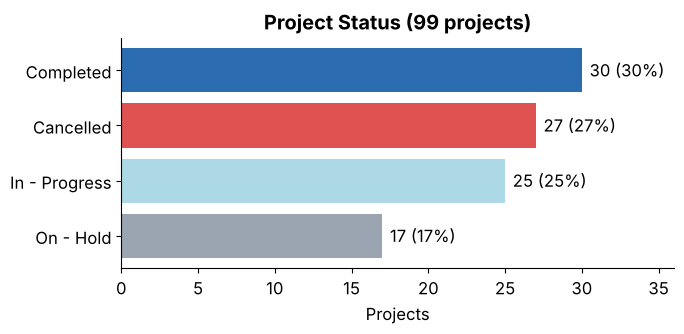

In [3]:
status = df['Status'].value_counts().reindex(['Completed', 'Cancelled', 'In - Progress', 'On - Hold'])
display(pd.DataFrame({'Projects': status, '%': status / len(df) * 100}))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(status.index[::-1], status.values[::-1], color=[STATUS_COLORS[s] for s in status.index[::-1]])
for i, v in enumerate(status.values[::-1]): ax.text(v + 0.5, i, f'{v} ({v/len(df):.0%})', va='center')
ax.set(title='Project Status (99 projects)', xlabel='Projects', xlim=(0, 36))
fig.tight_layout(); fig.savefig(FIG_DIR / 'status.png', dpi=150); plt.show()

## 3. When are projects cancelled, and what does it cost?

,count,min,median,max
Status,,,,
Cancelled,27.00,72.00,82.00,90.00
Completed,30.00,100.00,100.00,100.00
In - Progress,25.00,73.00,79.00,93.00
On - Hold,17.00,72.00,81.00,92.00


Cost already committed to cancelled projects: 116.8M (28% of portfolio cost)
Planned benefit of cancelled projects: 239.4M (27% of portfolio benefit)


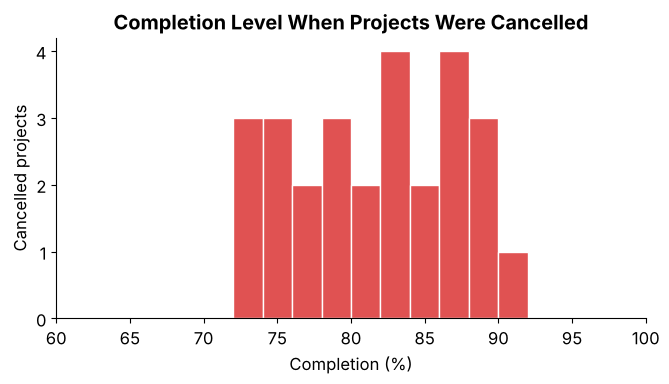

In [4]:
display(df.groupby('Status')['Completion'].describe()[['count', 'min', '50%', 'max']].rename(columns={'50%': 'median'}))

cancelled = df[df['Status'] == 'Cancelled']
print(f"Cost already committed to cancelled projects: {cancelled['Cost'].sum()/1e6:,.1f}M "
      f"({cancelled['Cost'].sum()/df['Cost'].sum():.0%} of portfolio cost)")
print(f"Planned benefit of cancelled projects: {cancelled['Benefit'].sum()/1e6:,.1f}M "
      f"({cancelled['Benefit'].sum()/df['Benefit'].sum():.0%} of portfolio benefit)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cancelled['Completion'], bins=range(70, 102, 2), color=RED, edgecolor='white')
ax.set(title='Completion Level When Projects Were Cancelled', xlabel='Completion (%)', ylabel='Cancelled projects', xlim=(60, 100))
fig.tight_layout(); fig.savefig(FIG_DIR / 'cancellation_completion.png', dpi=150); plt.show()

**Every cancelled project was at least 72% complete when it stopped** (median 82%). Projects are not being screened out early. They are dropped after most of the work and budget is spent, which is the most expensive time to cancel.

## 4. Does the business case predict success?

,Cost,Benefit,ROI
Status,,,
Cancelled,"4,170,710.00","8,895,516.00",2.12
Completed,"4,349,466.00","8,899,889.50",2.04
In - Progress,"4,172,827.00","8,697,391.00",2.13
On - Hold,"3,685,580.00","8,846,243.00",2.41


Cost     Kruskal-Wallis H = 1.90, p = 0.59
Benefit  Kruskal-Wallis H = 6.99, p = 0.07
ROI      Kruskal-Wallis H = 1.52, p = 0.68


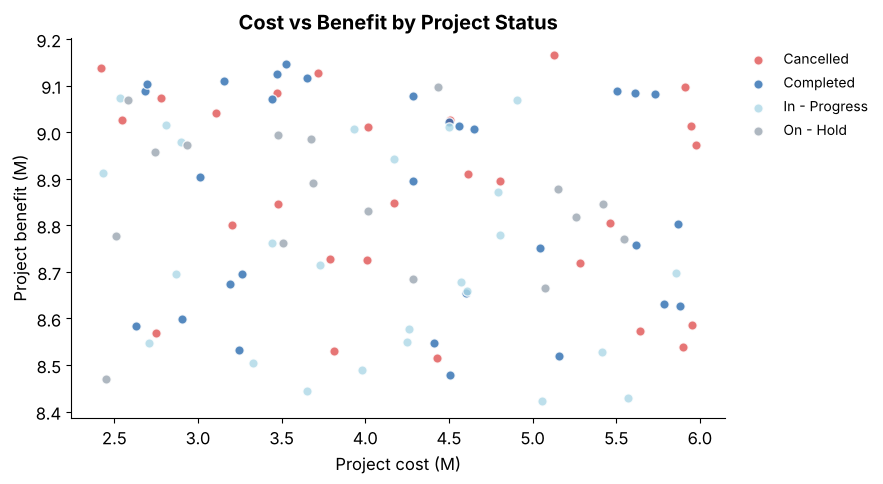

In [5]:
display(df.groupby('Status')[['Cost', 'Benefit', 'ROI']].median())
for col in ['Cost', 'Benefit', 'ROI']:
    h, p = stats.kruskal(*[g[col] for _, g in df.groupby('Status')])
    print(f'{col:<8} Kruskal-Wallis H = {h:.2f}, p = {p:.2f}')

fig, ax = plt.subplots(figsize=(9, 5))
for s, g in df.groupby('Status'):
    ax.scatter(g['Cost'] / 1e6, g['Benefit'] / 1e6, s=45, alpha=0.8, color=STATUS_COLORS[s], label=s, edgecolor='white')
ax.set(title='Cost vs Benefit by Project Status', xlabel='Project cost (M)', ylabel='Project benefit (M)')
ax.legend(frameon=False, fontsize=10, loc='upper left', bbox_to_anchor=(1.01, 1)); fig.tight_layout(); fig.savefig(FIG_DIR / 'cost_benefit.png', dpi=150); plt.show()

Cancelled projects look the same on paper as completed ones. Median ROI is about 2.1× for both. Cost and ROI show no difference (p = 0.59, 0.68), and benefit only a weak, non-significant one (p = 0.07). **The approval criteria (cost and benefit) say nothing about which projects will be delivered**, so other risk factors need to be part of the decision.

## 5. Are cancellations concentrated anywhere?

In [6]:
rows = []
for factor in ['Department', 'Complexity', 'Project Type', 'Project Manager', 'Region', 'Year']:
    table = pd.crosstab(df[factor], df['Cancelled'])
    p = stats.chi2_contingency(table)[1]
    rates = df.groupby(factor)['Cancelled'].mean()
    rows.append([factor, f'{rates.min():.0%} – {rates.max():.0%}', rates.idxmax(), p])
pd.DataFrame(rows, columns=['Factor', 'Cancellation rate range', 'Highest', 'Chi-square p'])

,Factor,Cancellation rate range,Highest,Chi-square p
0,Department,17% – 35%,eCommerce,0.66
1,Complexity,21% – 33%,Low,0.55
2,Project Type,18% – 36%,PROCESS IMPROVEMENT,0.59
3,Project Manager,7% – 47%,Brenda Chandler,0.17
4,Region,24% – 33%,South,0.86
5,Year,6% – 38%,2024,0.27


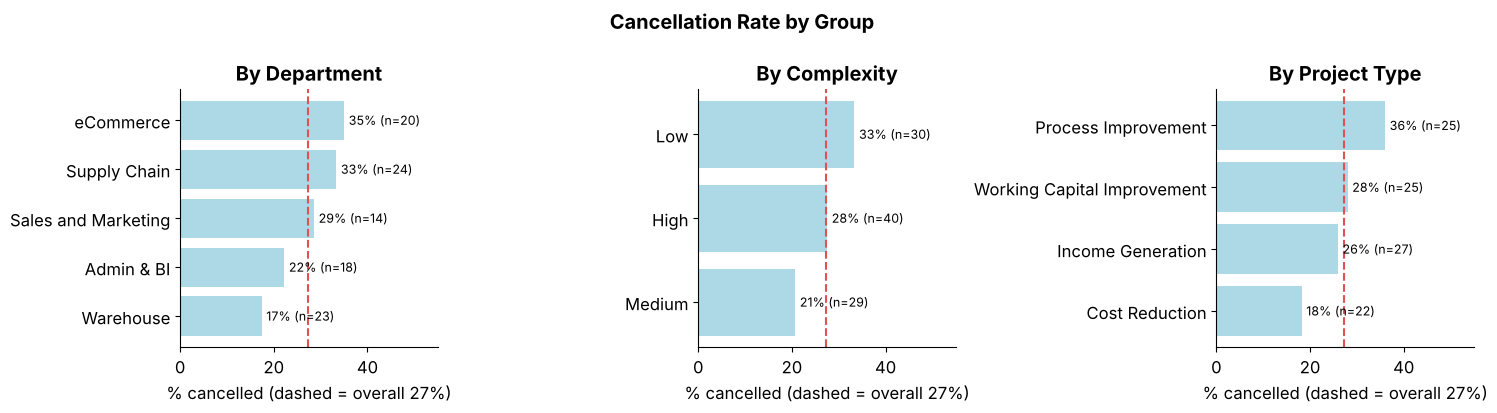

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
fig.suptitle('Cancellation Rate by Group', fontweight='bold')
for ax, factor in zip(axes, ['Department', 'Complexity', 'Project Type']):
    g = df.groupby(factor)['Cancelled'].agg(['mean', 'size']).sort_values('mean')
    labels = g.index.str.title() if factor == 'Project Type' else g.index
    ax.barh(labels, g['mean'] * 100, color=LIGHT_BLUE)
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])): ax.text(m * 100 + 1, i, f'{m:.0%} (n={n})', va='center', fontsize=9)
    ax.axvline(df['Cancelled'].mean() * 100, color=RED, ls='--', lw=1.5)
    ax.set(title=f'By {factor}', xlabel='% cancelled (dashed = overall 27%)', xlim=(0, 55))
fig.tight_layout(); fig.savefig(FIG_DIR / 'cancellation_by_factor.png', dpi=150); plt.show()

eCommerce (35%), Supply Chain (33%) and Process Improvement projects (36%) are cancelled most often, and Warehouse (17%) and Cost Reduction (18%) least. **With 14–40 projects per group, these differences are within what random variation would produce** (all p ≥ 0.17). Directing extra oversight at one department would not be supported by this evidence. Cancellations look like a portfolio-wide governance issue.

## 6. Progress by phase and over time

,size,median,mean
Phase,,,
Phase 1 - Explore,7,77.00,80.14
Phase 2 - Develop,7,80.00,81.43
Phase 3 - Plan,6,80.00,81.67
Phase 4 - Implement,13,80.00,81.08
Phase 5 - Measure,9,81.00,83.11


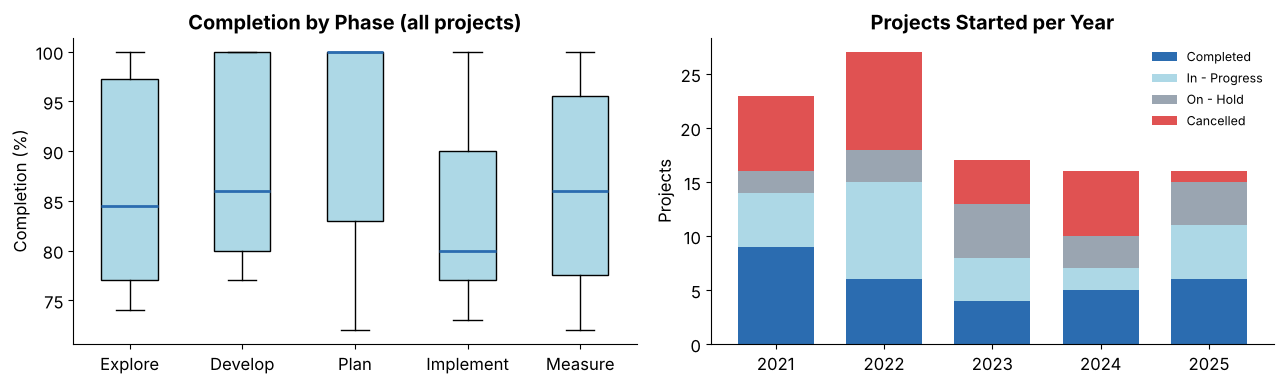

In [8]:
active = df[df['Status'].isin(['In - Progress', 'On - Hold'])]
display(active.groupby('Phase')['Completion'].agg(['size', 'median', 'mean']))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = sorted(df['Phase'].unique())
axes[0].boxplot([df.loc[df.Phase == ph, 'Completion'] for ph in order], tick_labels=[p.split(' - ')[1] for p in order],
                patch_artist=True, boxprops=dict(facecolor=LIGHT_BLUE), medianprops=dict(color=BLUE, lw=2))
axes[0].set(title='Completion by Phase (all projects)', ylabel='Completion (%)')
yearly = pd.crosstab(df['Year'], df['Status'])[['Completed', 'In - Progress', 'On - Hold', 'Cancelled']]
yearly.plot(kind='bar', stacked=True, ax=axes[1], color=[STATUS_COLORS[c] for c in yearly.columns], width=0.7)
axes[1].set(title='Projects Started per Year', xlabel='', ylabel='Projects'); axes[1].legend(frameon=False, fontsize=9)
axes[1].tick_params(axis='x', rotation=0)
fig.tight_layout(); fig.savefig(FIG_DIR / 'phase_and_year.png', dpi=150); plt.show()

* **Implementation (Phase 4) has the lowest median completion (80%) across all projects.** It's the natural point for a formal checkpoint. Among projects still open, completion is similar (77–81%) in every phase.
* **New project starts peaked in 2022 (27)** and fell to 16–17 per year afterwards. Many 2024–2025 projects are still open, so their final cancellation rate isn't known yet.

## 7. Recommendations
1. **Introduce stage-gate reviews.** Hold a formal go/no-go decision at the end of Planning (Phase 3), before implementation spend begins. Stopping a weak project at 40% complete costs far less than stopping it at 82%.
2. **Broaden approval criteria.** Cost and benefit don't distinguish successful projects. Add resource capacity, sponsor commitment and dependency risk to the approval scorecard.
3. **Record why projects are cancelled.** The data has no cancellation reason, which is the biggest gap. A required reason field (budget, priority change, scope, resources) would make root causes measurable.
4. **Treat this as a portfolio-level issue.** No department or manager stands out statistically, so a PMO-level review process will help more than targeting individual teams.
5. **Clear the on-hold backlog.** 17% of projects are on hold. Decide to resume or close each one to free up resources.

## Limitations
* Only 99 projects, so moderate differences between groups can't be detected reliably.
* The dataset appears to be simulated (nearly every project lasts about 3 months), and no currency is given.